In [1]:
import torch
import pyro
from mmbo.training import do_svi
from mmbo.nn import RegBNN, LayeredRegBNN, RegBNNGuide, LayeredRegBNNGuide
from mmbo.nn import posterior_samples
from mmbo.nn import predictor
from mmbo_v1.nn import RegBNN as RegBNN_v1, LayeredRegBNN as LayeredRegBNN_v1, RegBNNGuide as RegBNNGuide_v1, LayeredRegBNNGuide as LayeredRegBNNGuide_v1
from mmbo_v1.training import do_svi as do_svi_v1
from mmbo_v1.nn import posterior_samples as posterior_samples_v1
from mmbo_v1.nn import predictor as predictor_v1

from mmbo.examples.demo import paciorek_demo

import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
import math

# Unpack the included data from dictionary
X_train_main = paciorek_demo["X_train_main"]
X_train_mm =   paciorek_demo["X_train_mm"]
X_test =       paciorek_demo["X_test"]
Y_train_main = paciorek_demo["Y_train_main"]
Y_train_mm =   paciorek_demo["Y_train_mm"]
Y_test_main =  paciorek_demo["Y_test_main"]
Y_test_mm =    paciorek_demo["Y_test_mm"]

c:\Users\itaylor\Documents\DS4MEMS\mmbo\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
# Make sure we're using the package version we want to
from importlib.metadata import version
print(version("mmbo"))
print(version("mmbo_v1"))

2.0.0
1.0.0


In [3]:
learning_rate = 0.001
n_samples = 1000 # Number of posterior samples to use
# reproducibility 
seed = 2027

## Version 1

In [4]:
# reproducibility
torch.manual_seed(seed)

In [5]:

# Initialize the model: from_data method uses training data to set input/output
# dimensions and normalizer layersl It also stores the training data within the model,
# so that no data needs to be passed during training.
model_single_v1 = RegBNN_v1.from_data(X_train_main, Y_train_main, hidden_widths = [256, 256], prior_variance = 0.01)

# Initialize the guide: uses model to reference layers and their widths, and
# priors if custom hyperparemters are supplied.
guide_single_v1 = RegBNNGuide_v1(model_single_v1)

In [6]:
adam_v1 = pyro.optim.Adam({"lr": learning_rate})
elbo_v1 = pyro.infer.Trace_ELBO(num_particles = 1)
# model,guide are created by code like above
svi_v1 = pyro.infer.SVI(model_single_v1, guide_single_v1, adam_v1, elbo_v1)

# The optional params argument can be used to restart training from a
# previously returned set of parameters (e.g. with a smaller learning
# rate).
params_single_v1, losses_single_v1 = do_svi_v1(svi_v1, params = None, X_train = X_train_main, Y_train = Y_train_main)

2026-11-02 17:11:15 - Start


c:\Users\itaylor\Documents\DS4MEMS\mmbo\.venv\Lib\site-packages\pyro\distributions\torch_distribution.py:49: UserWarning: Singular sample detected.
  self.rsample(sample_shape)


2026-11-02 17:12:05 - Step 1000, Elbo loss: 48812.0 +/- 29641.4 (slope = -50861.882 +/- 430.653 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:12:50 - Step 2000, Elbo loss: 16791.9 +/- 10240.9 (slope = -17555.449 +/- 156.639 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:13:42 - Step 3000, Elbo loss: 5915.1 +/- 3412.6 (slope = -5844.981 +/- 54.394 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:14:26 - Step 4000, Elbo loss: 2290.2 +/- 1147.2 (slope = -1963.333 +/- 18.959 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:15:09 - Step 5000, Elbo loss: 1061.2 +/- 391.9 (slope = -667.696 +/- 7.619 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:15:52 - Step 6000, Elbo loss: 645.3 +/- 136.9 (slope = -228.224 +/- 4.035 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:16:35 - Step 7000, Elbo loss: 498.5 +/- 55.9 (slope = -85.267 +/- 2.887 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:17:20 - Step 8000, Elbo loss: 442.2 +/- 31.2 (slope = -33.590 +/- 2.672 loss/k-iter, p-value = 0.000) + 
2026-11-02 

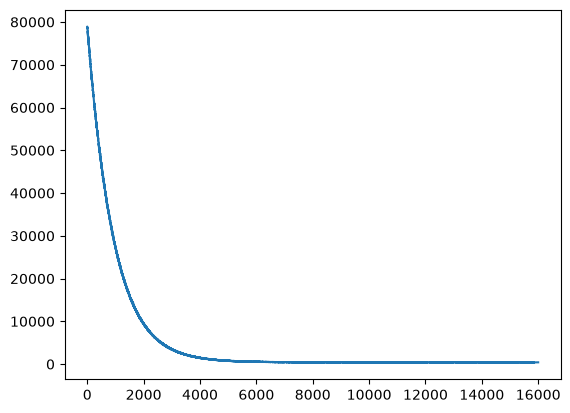

In [7]:
plt.plot(losses_single_v1)

In [8]:
samples_single_v1 = posterior_samples_v1(guide_single_v1, params_single_v1, n_samples, X_train = X_train_main, Y_train = Y_train_main)

In [9]:
pred_single_v1 = predictor_v1(model_single_v1, samples_single_v1)
Y_test_pred_single_v1 = pred_single_v1(X_test)
Y_train_pred_single_v1 = pred_single_v1(X_train_main)

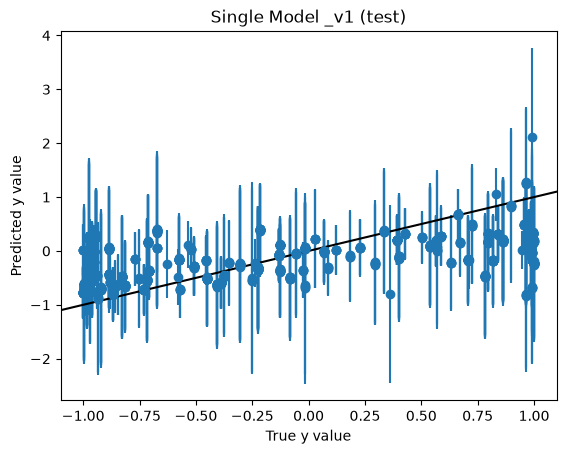

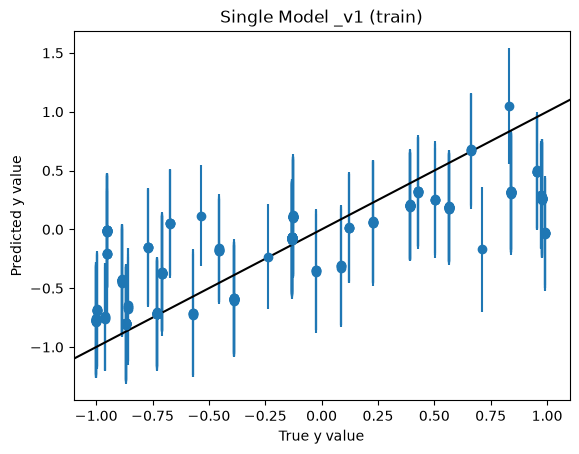

In [10]:
plt.errorbar(Y_test_main, Y_test_pred_single_v1.mean(dim=0).squeeze(), yerr = 1.96 * Y_test_pred_single_v1.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_test_main, Y_test_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model _v1 (test)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.errorbar(Y_train_main, Y_train_pred_single_v1.mean(dim=0).squeeze(), yerr = 1.96 * Y_train_pred_single_v1.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_train_main, Y_train_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model _v1 (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

## Version 2

In [11]:
# reproducibility
torch.manual_seed(seed)

In [12]:

# Initialize the model: from_data method uses training data to set input/output
# dimensions and normalizer layersl It also stores the training data within the model,
# so that no data needs to be passed during training.
model_single = RegBNN.from_data(X_train_main, Y_train_main, hidden_widths = [256, 256], prior_variance = 0.01)

# Initialize the guide: uses model to reference layers and their widths, and
# priors if custom hyperparemters are supplied.
guide_single = RegBNNGuide(model_single)

In [13]:


adam = pyro.optim.Adam({"lr": learning_rate})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
# model,guide are created by code like above
svi = pyro.infer.SVI(model_single, guide_single, adam, elbo)

# The optional params argument can be used to restart training from a
# previously returned set of parameters (e.g. with a smaller learning
# rate).
params_single, losses_single = do_svi(svi, params = None, X_train = X_train_main, Y_train = Y_train_main)

2026-11-02 17:24:05 - Start
2026-11-02 17:24:55 - Step 1000, Elbo loss: 48816.8 +/- 29617.7 (slope = -50820.511 +/- 430.654 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:25:40 - Step 2000, Elbo loss: 16795.0 +/- 10238.2 (slope = -17548.442 +/- 157.660 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:26:40 - Step 3000, Elbo loss: 5917.5 +/- 3420.1 (slope = -5857.674 +/- 54.579 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:27:39 - Step 4000, Elbo loss: 2290.2 +/- 1152.1 (slope = -1971.241 +/- 19.220 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:28:34 - Step 5000, Elbo loss: 1060.7 +/- 393.6 (slope = -670.504 +/- 7.708 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:29:30 - Step 6000, Elbo loss: 646.6 +/- 137.5 (slope = -229.344 +/- 4.050 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:30:24 - Step 7000, Elbo loss: 498.1 +/- 56.2 (slope = -85.882 +/- 2.904 loss/k-iter, p-value = 0.000) + 
2026-11-02 17:31:19 - Step 8000, Elbo loss: 442.5 +/- 32.4 (slope = -36.540 +/- 2.689 loss/k-iter, p-v

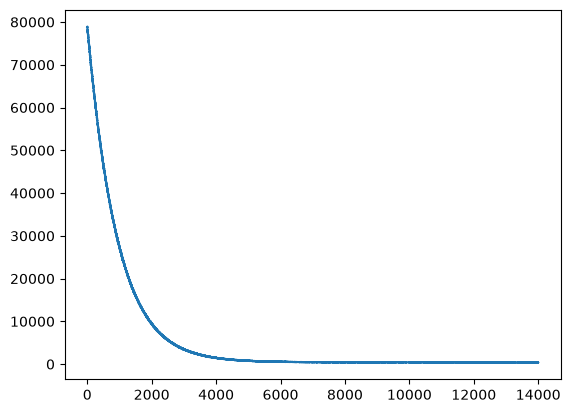

In [14]:
plt.plot(losses_single)

In [15]:

samples_single = posterior_samples(guide_single, params_single, n_samples, X_train = X_train_main, Y_train = Y_train_main)

In [16]:
pred_single = predictor(model_single, samples_single)
Y_test_pred_single = pred_single(X_test)
Y_train_pred_single = pred_single(X_train_main)

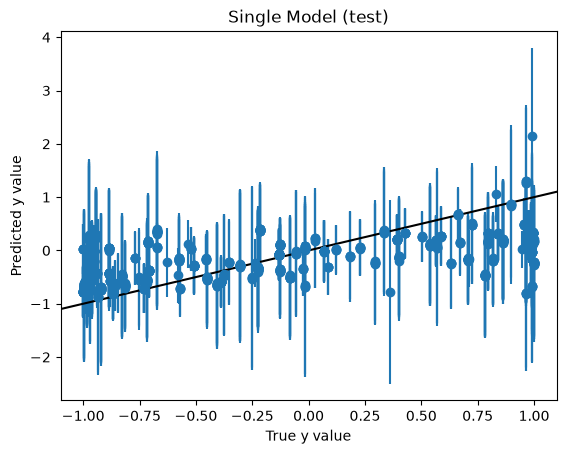

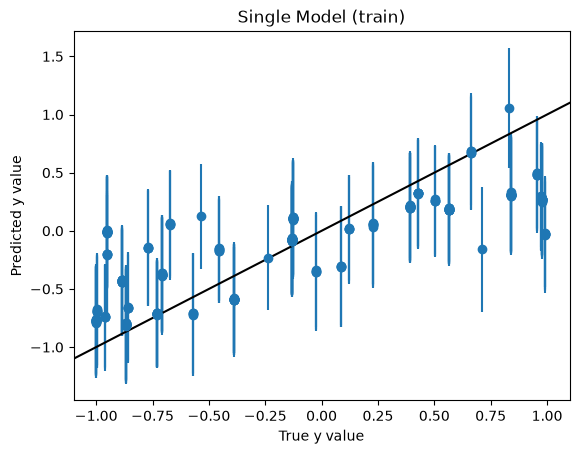

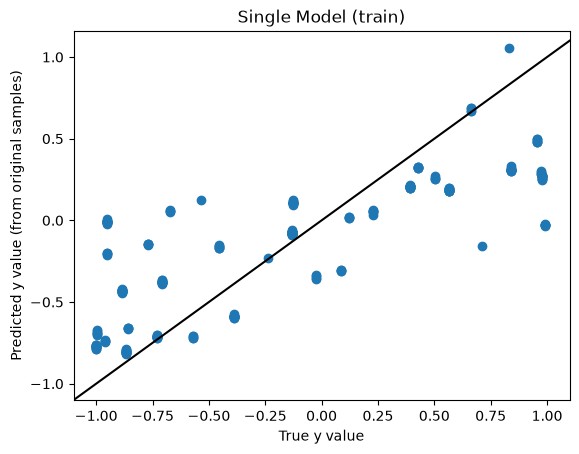

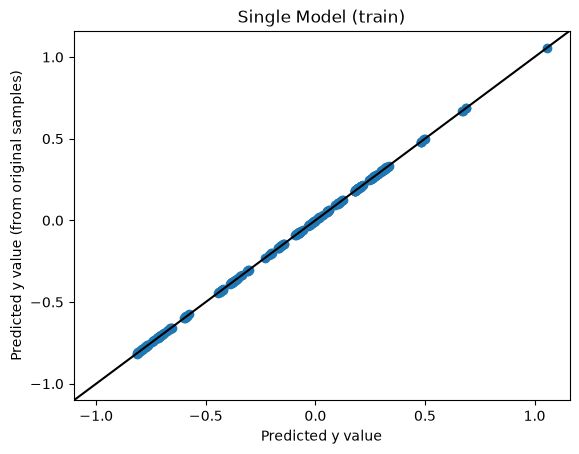

In [17]:
plt.errorbar(Y_test_main, Y_test_pred_single.mean(dim=0).squeeze(), yerr = 1.96 * Y_test_pred_single.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_test_main, Y_test_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (test)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.errorbar(Y_train_main, Y_train_pred_single.mean(dim=0).squeeze(), yerr = 1.96 * Y_train_pred_single.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_train_main, Y_train_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.scatter(Y_train_main, samples_single["train/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

plt.scatter(Y_train_pred_single.mean(dim=0), samples_single["train/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("Predicted y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

## Compare the distributions of stuff

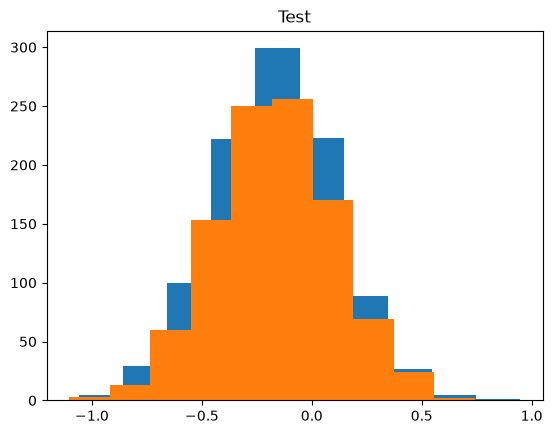

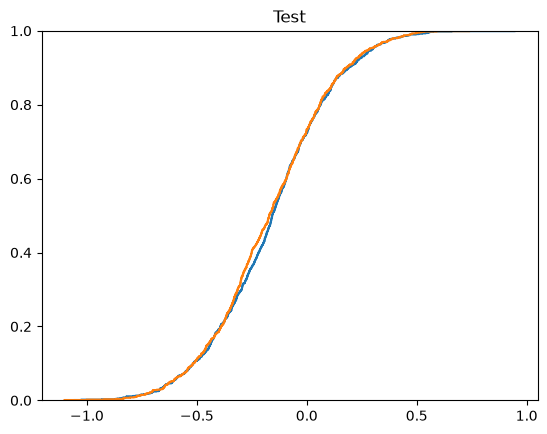

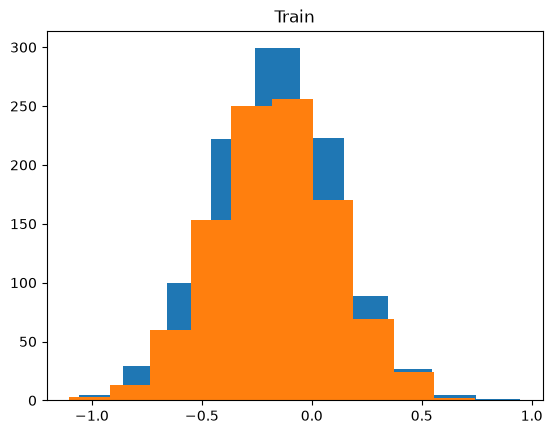

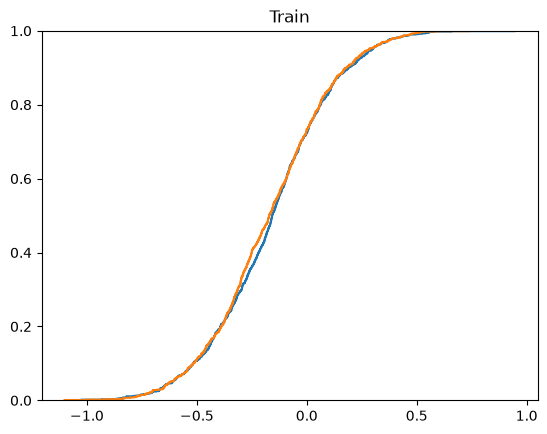

In [18]:
idx = 0
plt.hist(Y_test_pred_single[:,idx,0], label="v2")
plt.hist(Y_test_pred_single_v1[:,idx,0], label="v1")
plt.title("Test")
plt.show()

plt.ecdf(Y_test_pred_single[:,idx,0], label="v2")
plt.ecdf(Y_test_pred_single_v1[:,idx,0], label="v1")
plt.title("Test")
plt.show()

plt.hist(Y_train_pred_single[:,idx,0], label="v2")
plt.hist(Y_train_pred_single_v1[:,idx,0], label="v1")
plt.title("Train")
plt.show()

plt.ecdf(Y_train_pred_single[:,idx,0], label="v2")
plt.ecdf(Y_train_pred_single_v1[:,idx,0], label="v1")
plt.title("Train")
plt.show()

In [19]:
# Compute KS statistics of all of the predictions for train and test points

ks_stats_train = torch.zeros((Y_train_pred_single.shape[-2]))
ks_stats_test = torch.zeros((Y_test_pred_single.shape[-2]))
for idx in range(Y_train_pred_single.shape[-2]):
    ks_stats_train[idx] = torch.as_tensor(
        ks_2samp(
            Y_train_pred_single[:,idx,0],
            Y_train_pred_single_v1[:,idx,0]
        ).statistic
    )
for idx in range(Y_test_pred_single.shape[-2]):
    ks_stats_test[idx] = torch.as_tensor(
        ks_2samp(
            Y_test_pred_single[:,idx,0],
            Y_test_pred_single_v1[:,idx,0]
        ).statistic
    )

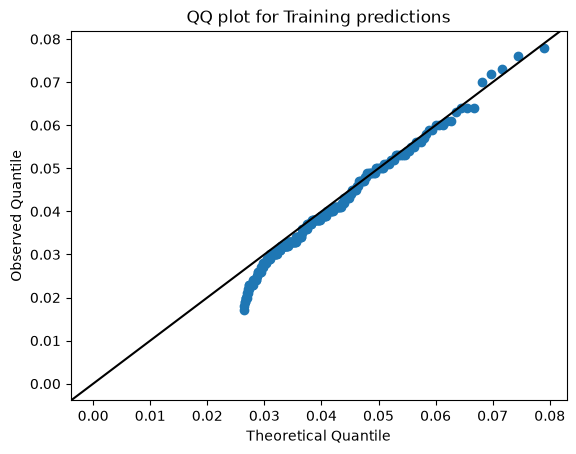

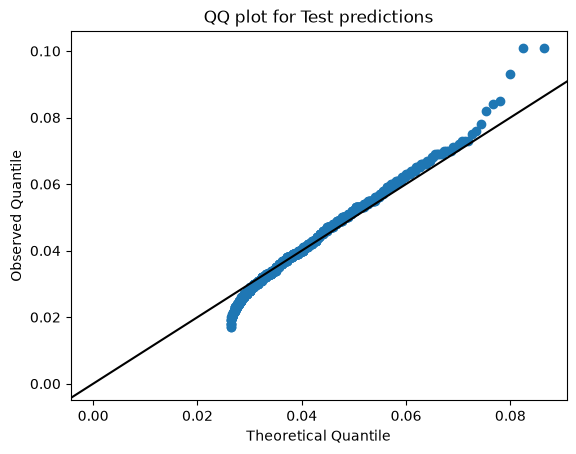

In [20]:
# Calculate theoretic KS quantiles for the same data
def ks_quantile(alpha: torch.Tensor, n: int, m: int):
    crit = torch.sqrt(-torch.log((1-alpha) / 2) / 2)
    return crit * math.sqrt((m + n) / (m*n))

def torch_pseudoobs(X: torch.Tensor):
    n = X.shape[0]
    return (X.argsort(dim=0).argsort(dim=0) + 1) / (n + 1)

ks_theory_train = ks_quantile(torch_pseudoobs(ks_stats_train), n_samples, n_samples)
ks_theory_test = ks_quantile(torch_pseudoobs(ks_stats_test), n_samples, n_samples)

plt.scatter(ks_theory_train, ks_stats_train)
plt.title("QQ plot for Training predictions")
plt.xlabel("Theoretical Quantile")
plt.ylabel("Observed Quantile")
plt.axline((0,0), (0.01,0.01), c="black")
plt.show()

plt.scatter(ks_theory_test, ks_stats_test)
plt.title("QQ plot for Test predictions")
plt.xlabel("Theoretical Quantile")
plt.ylabel("Observed Quantile")
plt.axline((0,0), (0.01,0.01), c="black")
plt.show()

In [21]:
params_single_v1["params"].keys()

dict_keys(['layers.0.0.loc', 'layers.0.0.scale', 'layers.0.1.scale_val', 'layers.1.0.loc', 'layers.1.0.scale', 'layers.1.1.scale_val'])